# Merge all cleaned datasets: EDA, cleaning, and preparation

Load all eight CSV files from `clean_dataset`, including the Sentinel-1 label/GFS supplement, inspect and clean them, then outer-merge daily sources so the combined file retains the 2026 extension. The new `flood_obs` is canonical; conflicting historical labels remain in `flood_obs_legacy` for audit.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
EXPECTED_FILES = [
    "sea_level_clean.csv",
    "humidity_pressure_soil_clean.csv",
    "river_level_clean.csv",
    "flood_history_clean.csv",
    "rain_clean.csv",
    "static_terrain_soil_clean.csv",
    "4_flood_recurrence.csv",
    "nst_label_gfs_2020-01-01_to_2026-11-22.csv",
]
DAILY_FILES = [
    "sea_level_clean.csv",
    "humidity_pressure_soil_clean.csv",
    "river_level_clean.csv",
    "flood_history_clean.csv",
    "rain_clean.csv",
    "nst_label_gfs_2020-01-01_to_2026-11-22.csv",
]
DAILY_KEYS = ["date", "unit_level", "district_code"]
DISTRICT_KEYS = ["unit_level", "district_code"]
SOURCE_PLOT_COLUMNS = {
    "sea_level_clean.csv": ["sea_level_cmems_m", "sea_level_hycom_mean_m", "sea_level_hycom_max_m", "sea_level_hycom_min_m"],
    "humidity_pressure_soil_clean.csv": ["rh_pct", "temp_c", "pressure_hpa", "soil_l1"],
    "river_level_clean.csv": ["river_water_frac", "corridor_valid_frac", "dry_river_water_frac", "river_water_ha"],
    "flood_history_clean.csv": ["flood_obs", "flood_ha", "valid_frac", "n_scenes"],
    "nst_label_gfs_2020-01-01_to_2026-11-22.csv": ["flood_obs", "valid_frac", "rain_next_24h_mm", "rain_next_72h_mm"],
    "rain_clean.csv": ["rain_chirps_mm", "rain_imerg_mm", "rain_minutes", "rain_7d"],
    "static_terrain_soil_clean.csv": ["elevation_m", "slope_deg", "bowl_frac", "hand_m"],
    "4_flood_recurrence.csv": ["flood_freq_mean", "flood_count_mean", "flood_ever_ha", "recurrent_ge2_ha"],
}

project_dir = next(
    (path for path in [Path.cwd(), *Path.cwd().parents]
     if (path / "clean_dataset").is_dir()),
    None,
)
if project_dir is None:
    raise FileNotFoundError(f"Cannot find clean_dataset from {Path.cwd()}")
clean_dir = project_dir / "clean_dataset"
found_files = sorted(path.name for path in clean_dir.glob("*.csv"))
missing_files = sorted(set(EXPECTED_FILES) - set(found_files))
unexpected_files = sorted(set(found_files) - set(EXPECTED_FILES))
if missing_files or unexpected_files:
    raise ValueError(
        f"CSV inventory mismatch in {clean_dir}; missing={missing_files}, unexpected={unexpected_files}"
    )

source_frames = {}
for filename in EXPECTED_FILES:
    options = {"encoding": "utf-8-sig", "low_memory": False}
    if filename in DAILY_FILES:
        options["parse_dates"] = ["date"]
    frame = pd.read_csv(clean_dir / filename, **options)
    if filename == "nst_label_gfs_2020-01-01_to_2026-11-22.csv":
        frame["unit_level"] = "amphoe"
    source_frames[filename] = frame

print(f"Data folder: {clean_dir}")
print("CSV files loaded:")
display(pd.DataFrame([
    {
        "file": filename,
        "rows": len(frame),
        "columns": len(frame.columns),
        "missing_cells": int(frame.isna().sum().sum()),
        "date_start": frame["date"].min() if "date" in frame.columns else None,
        "date_end": frame["date"].max() if "date" in frame.columns else None,
        "periods": ", ".join(sorted(frame["period"].astype(str).unique())) if "period" in frame.columns else None,
    }
    for filename, frame in source_frames.items()
]))


Data folder: c:\Users\sitti\OneDrive\Desktop\Nahh ahhh v4\clean_dataset
CSV files loaded:


,file,rows,columns,missing_cells,date_start,date_end,periods
0,sea_level_clean.csv,41648,18,44232,2020-01-01,2025-12-31,None
1,humidity_pressure_soil_clean.csv,41648,45,39456,2020-01-01,2025-12-31,None
2,river_level_clean.csv,41648,22,133636,2020-01-01,2025-12-31,None
3,flood_history_clean.csv,41648,21,93942,2020-01-01,2025-12-31,None
4,rain_clean.csv,41648,21,0,2020-01-01,2025-12-31,None
5,static_terrain_soil_clean.csv,19,26,1,NaT,NaT,None
6,4_flood_recurrence.csv,133,11,0,NaT,NaT,"2020, 2021, 2022, 2023, 2024, 2025, all"
7,nst_label_gfs_2020-01-01_to_2026-11-22.csv,45324,31,351090,2020-01-01,2026-11-22,None


## 1. EDA: inspect each input before merging


### sea_level_clean.csv
Shape: (41648, 18)
Date range: 2020-01-01 to 2025-12-31
Duplicate key rows: 0
Missing values by column:


,missing_rows
sea_level_cmems_m,16758
sea_level_hycom_min_m,9158
sea_level_hycom_max_m,9158
sea_level_hycom_mean_m,9158
year,0
date,0
unit_level,0
month,0
doy,0
day,0


,count,mean,std,min,25%,50%,75%,max
sea_level_cmems_m,24890.0,0.701,0.103,0.467,0.624,0.677,0.767,1.029
sea_level_hycom_mean_m,32490.0,0.646,0.069,0.434,0.596,0.639,0.692,0.875
sea_level_hycom_max_m,32490.0,0.678,0.072,0.464,0.624,0.671,0.724,0.923
sea_level_hycom_min_m,32490.0,0.614,0.068,0.404,0.566,0.608,0.659,0.825
sea_level_cmems_m_missing,41648.0,0.402,0.490,0.000,0.000,0.000,1.000,1.000
sea_level_hycom_mean_m_missing,41648.0,0.220,0.414,0.000,0.000,0.000,0.000,1.000
sea_level_hycom_max_m_missing,41648.0,0.220,0.414,0.000,0.000,0.000,0.000,1.000
sea_level_hycom_min_m_missing,41648.0,0.220,0.414,0.000,0.000,0.000,0.000,1.000
sea_level_available_count,41648.0,2.938,1.120,1.000,3.000,3.000,4.000,4.000


,date,year,month,day,doy,unit_level,province,district,district_code,sea_level_cmems_m,sea_level_hycom_mean_m,sea_level_hycom_max_m,sea_level_hycom_min_m,sea_level_cmems_m_missing,sea_level_hycom_mean_m_missing,sea_level_hycom_max_m_missing,sea_level_hycom_min_m_missing,sea_level_available_count
0,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Bang Khan,26738,NaN,0.729109,0.771184,0.679884,1,0,0,0,3
1,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Cha-uat,26739,NaN,0.729109,0.771184,0.679884,1,0,0,0,3
2,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Chawang,26740,NaN,0.729109,0.771184,0.679884,1,0,0,0,3


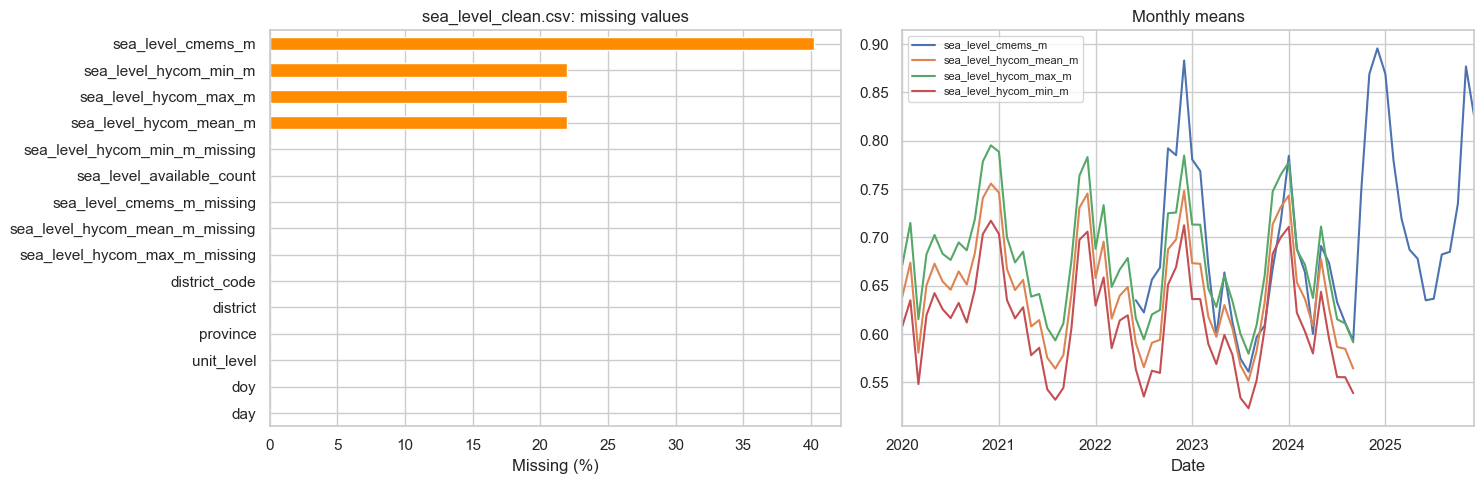

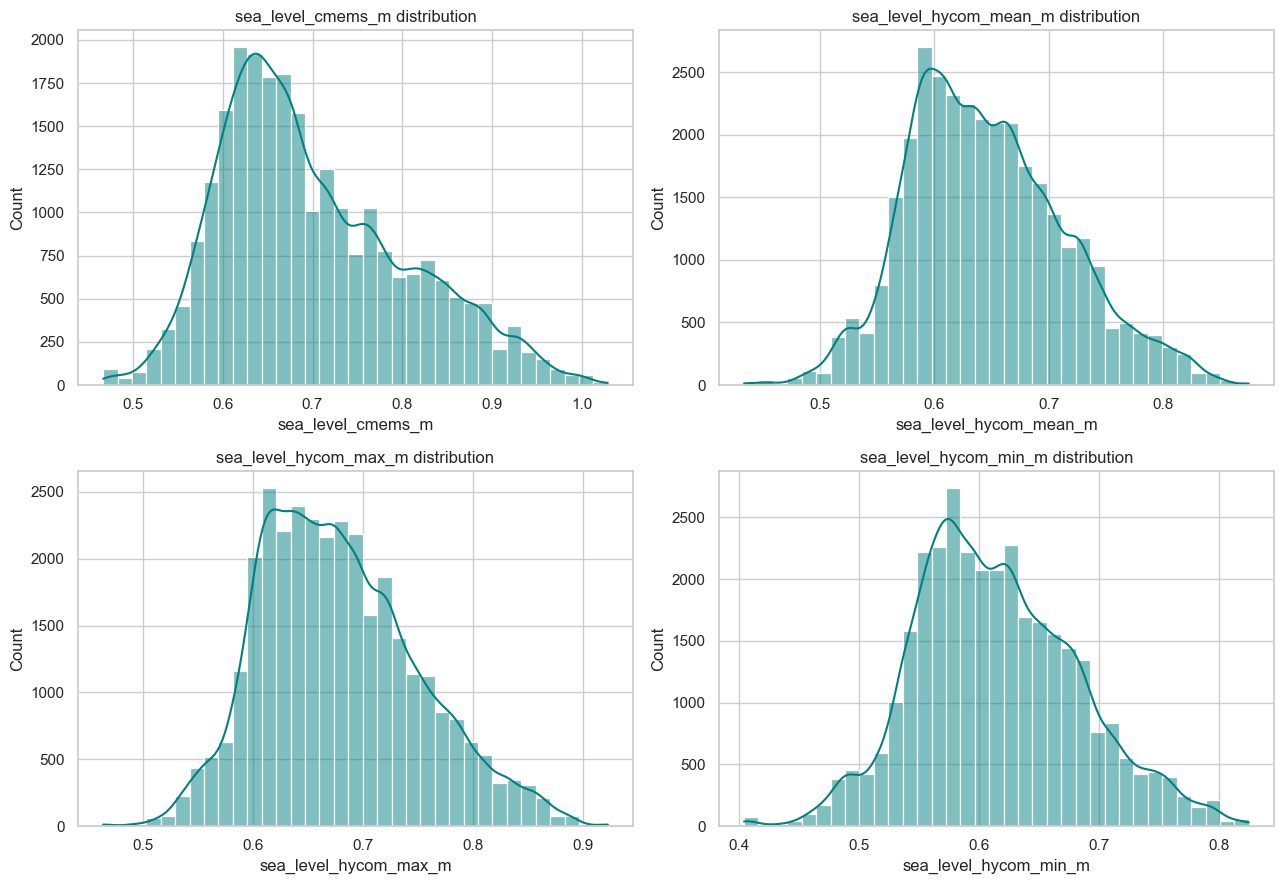


### humidity_pressure_soil_clean.csv
Shape: (41648, 45)
Date range: 2020-01-01 to 2025-12-31
Duplicate key rows: 0
Missing values by column:


,missing_rows
dewpoint_c,2192
rh_pct,2192
q_gkg,2192
temp_c,2192
soil_l2,2192
soil_l1,2192
rh_chg_pct,2192
rh_pct_after,2192
rh_pct_before,2192
pressure_chg_hpa,2192


,count,mean,std,min,25%,50%,75%,max
rh_pct,39456.0,82.771,7.543,48.766,78.629,83.547,88.060,99.354
q_gkg,39456.0,17.683,1.201,10.958,17.096,17.946,18.476,21.774
temp_c,39456.0,26.185,1.492,21.519,25.159,26.093,27.123,32.112
dewpoint_c,39456.0,22.944,1.201,14.946,22.346,23.211,23.757,26.613
pressure_hpa,39456.0,995.819,11.759,967.082,990.474,998.445,1005.750,1015.405
pressure_hpa_before,39456.0,996.070,11.809,966.587,990.707,998.724,1006.030,1015.536
pressure_hpa_after,39456.0,995.537,11.803,966.451,990.182,998.189,1005.478,1014.790
pressure_chg_hpa,39456.0,-0.533,0.856,-3.292,-1.122,-0.541,0.023,2.811
rh_pct_before,39456.0,94.145,3.878,64.789,92.263,95.032,96.988,99.824
rh_pct_after,39456.0,94.496,3.867,65.574,92.575,95.323,97.295,99.927


,date,year,month,day,doy,unit_level,province,district,district_code,rh_pct,...,rh_pct_before_missing,rh_pct_after_missing,rh_chg_pct_missing,soil_l1_missing,soil_l2_missing,soil_l3_missing,soil_l4_missing,soil_l1_before_missing,soil_l1_after_missing,soil_l1_chg_missing
0,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Bang Khan,26738,76.307780,...,0,0,0,0,0,0,0,0,0,0
1,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Cha-uat,26739,79.853417,...,0,0,0,0,0,0,0,0,0,0
2,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Chawang,26740,78.700284,...,0,0,0,0,0,0,0,0,0,0


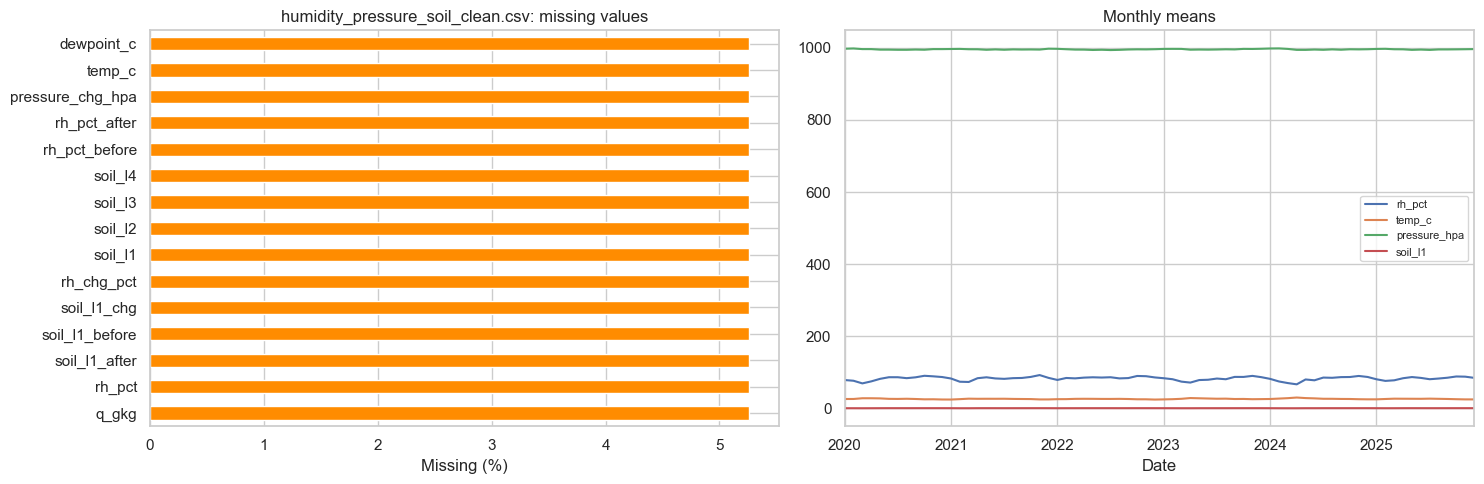

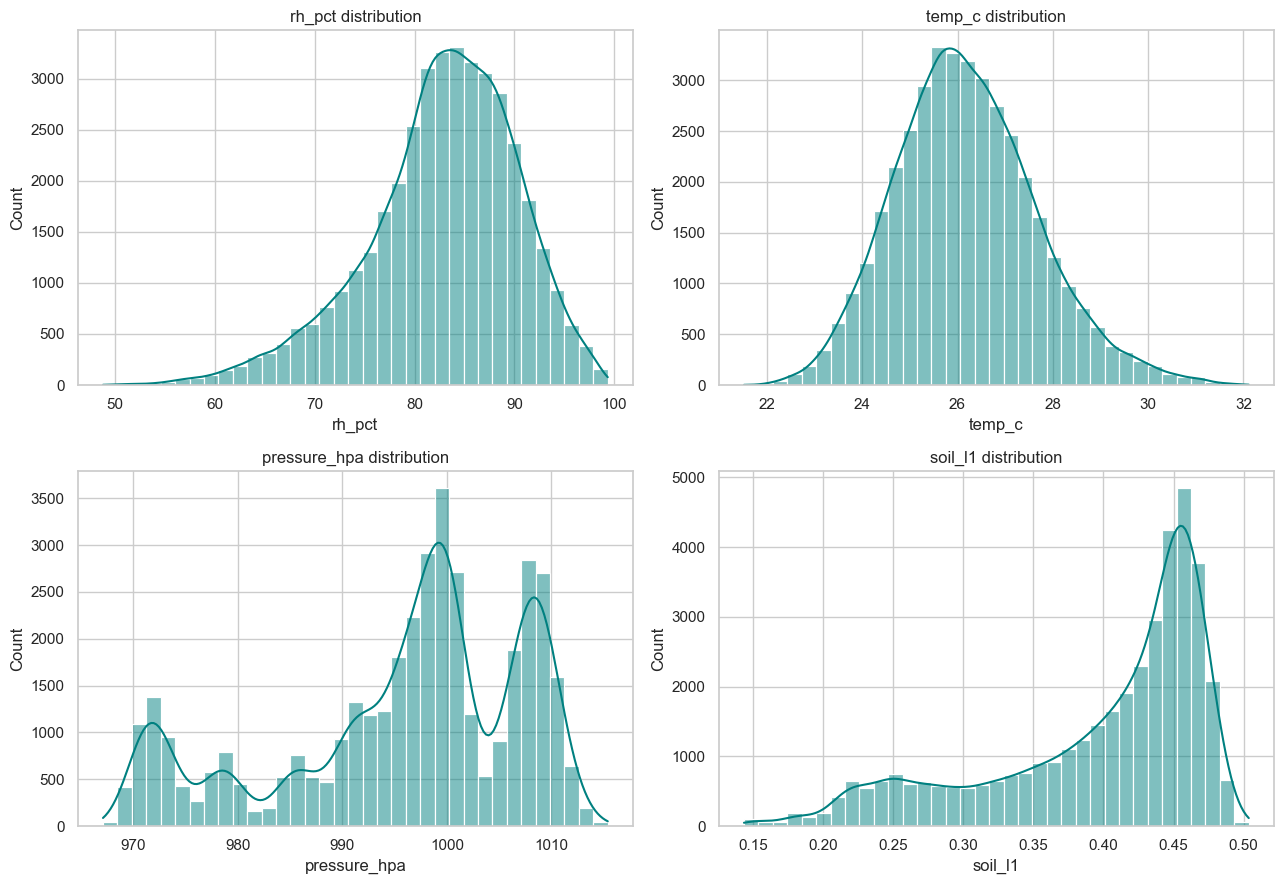


### river_level_clean.csv
Shape: (41648, 22)
Date range: 2020-01-01 to 2025-12-31
Duplicate key rows: 0
Missing values by column:


,missing_rows
river_water_frac,35518
river_water_ha,35518
river_water_excess,35518
corridor_valid_frac,24890
dry_river_water_frac,2192
date,0
unit_level,0
doy,0
day,0
month,0


,count,mean,std,min,25%,50%,75%,max
n_scenes,41648.0,0.835,1.079,0.000,0.000,0.000,2.000,4.000
river_water_frac,6130.0,0.016,0.020,0.000,0.002,0.006,0.025,0.094
corridor_valid_frac,16758.0,0.342,0.469,0.000,0.000,0.000,1.000,1.000
river_water_ha,6130.0,253.731,496.986,0.000,14.753,47.765,307.438,4584.138
dry_river_water_frac,39456.0,0.013,0.020,0.000,0.001,0.003,0.017,0.078
river_water_excess,6130.0,0.002,0.008,-0.036,0.000,0.001,0.002,0.076
corridor_ha,41648.0,18596.281,37627.301,0.000,5763.870,8795.714,15184.310,176666.300
river_water_frac_missing,41648.0,0.853,0.354,0.000,1.000,1.000,1.000,1.000
corridor_valid_frac_missing,41648.0,0.598,0.490,0.000,0.000,1.000,1.000,1.000
river_water_ha_missing,41648.0,0.853,0.354,0.000,1.000,1.000,1.000,1.000


,date,year,month,day,doy,unit_level,province,district,district_code,n_scenes,...,river_water_ha,dry_river_water_frac,river_water_excess,corridor_ha,river_water_frac_missing,corridor_valid_frac_missing,river_water_ha_missing,dry_river_water_frac_missing,river_water_excess_missing,river_observation_available
0,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Bang Khan,26738,0,...,NaN,0.000000,NaN,8795.713800,1,1,1,0,1,0
1,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Cha-uat,26739,0,...,NaN,0.015795,NaN,17987.277682,1,1,1,0,1,0
2,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Chawang,26740,0,...,NaN,0.001480,NaN,16703.384390,1,1,1,0,1,0


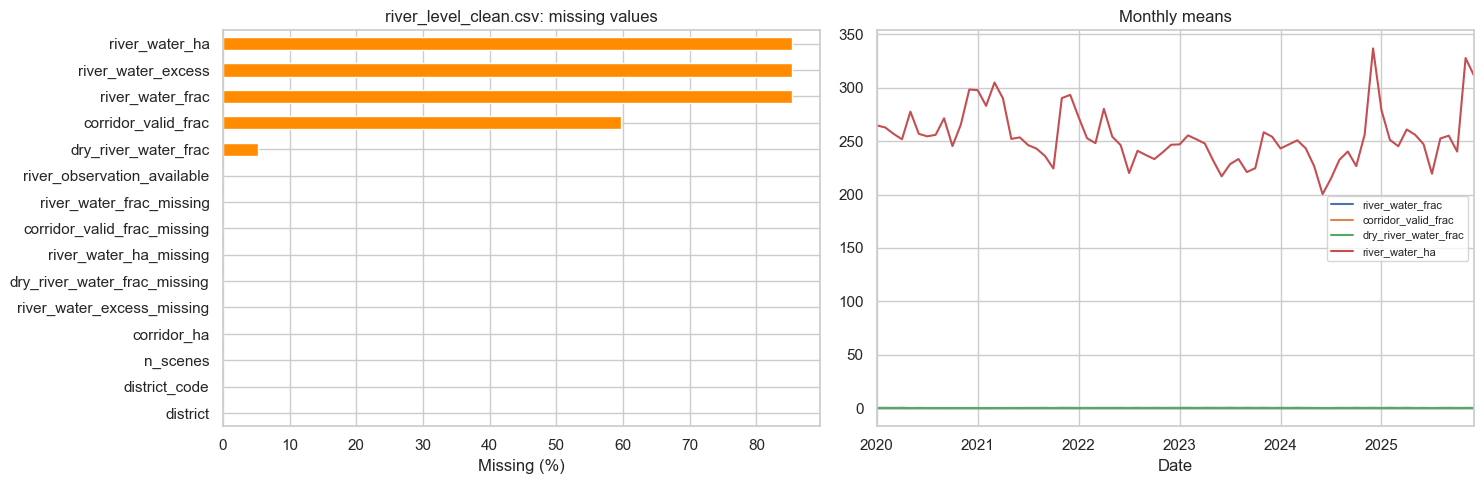

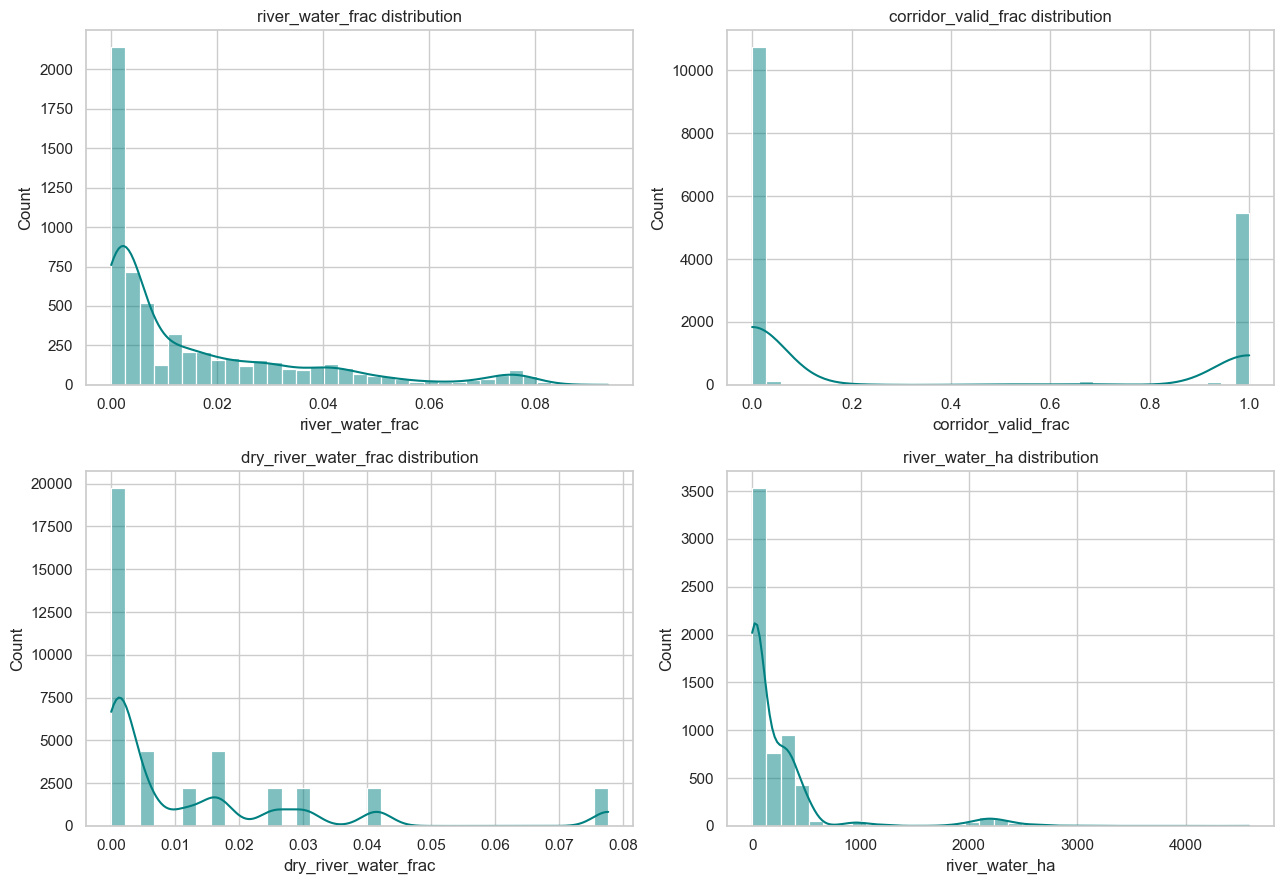


### flood_history_clean.csv
Shape: (41648, 21)
Date range: 2020-01-01 to 2025-12-31
Duplicate key rows: 0
Missing values by column:


,missing_rows
flood_obs,35299
flood_ha,34684
valid_frac,23959
year,0
date,0
doy,0
day,0
month,0
unit_level,0
district_code,0


,count,mean,std,min,25%,50%,75%,max
n_scenes,41648.0,0.835,1.079,0.0,0.000,0.000,2.000,4.000
flood_obs,6349.0,0.911,0.285,0.0,1.000,1.000,1.000,1.000
flood_ha,6964.0,2058.006,4827.638,0.0,248.528,947.056,1868.422,83155.972
valid_frac,17689.0,0.342,0.469,0.0,0.000,0.000,1.000,1.000
rule_water_db,41648.0,-16.000,0.000,-16.0,-16.000,-16.000,-16.000,-16.000
rule_diff_db,41648.0,-3.000,0.000,-3.0,-3.000,-3.000,-3.000,-3.000
rule_min_ha,41648.0,5.000,0.000,5.0,5.000,5.000,5.000,5.000
rule_min_cover,41648.0,0.800,0.000,0.8,0.800,0.800,0.800,0.800
flood_obs_missing,41648.0,0.848,0.359,0.0,1.000,1.000,1.000,1.000
flood_ha_missing,41648.0,0.833,0.373,0.0,1.000,1.000,1.000,1.000


,date,year,month,day,doy,unit_level,province,district,district_code,n_scenes,...,flood_ha,valid_frac,rule_water_db,rule_diff_db,rule_min_ha,rule_min_cover,flood_obs_missing,flood_ha_missing,valid_frac_missing,flood_obs_available
0,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Bang Khan,26738,0,...,NaN,NaN,-16,-3,5,0.8,1,1,1,0
1,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Cha-uat,26739,0,...,NaN,NaN,-16,-3,5,0.8,1,1,1,0
2,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Chawang,26740,0,...,NaN,NaN,-16,-3,5,0.8,1,1,1,0


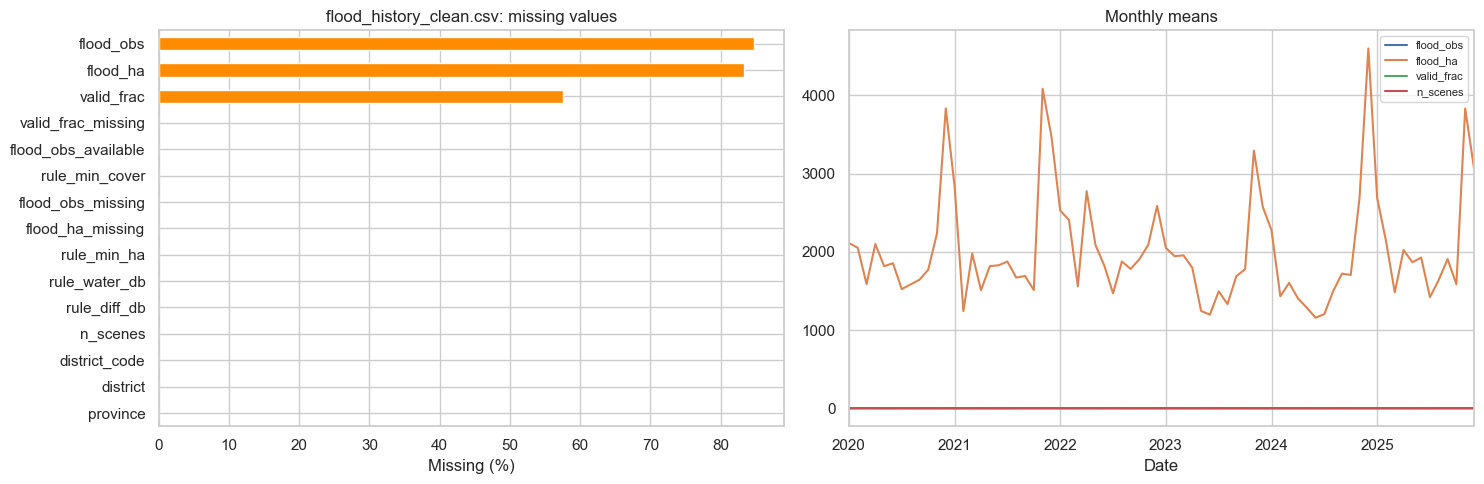

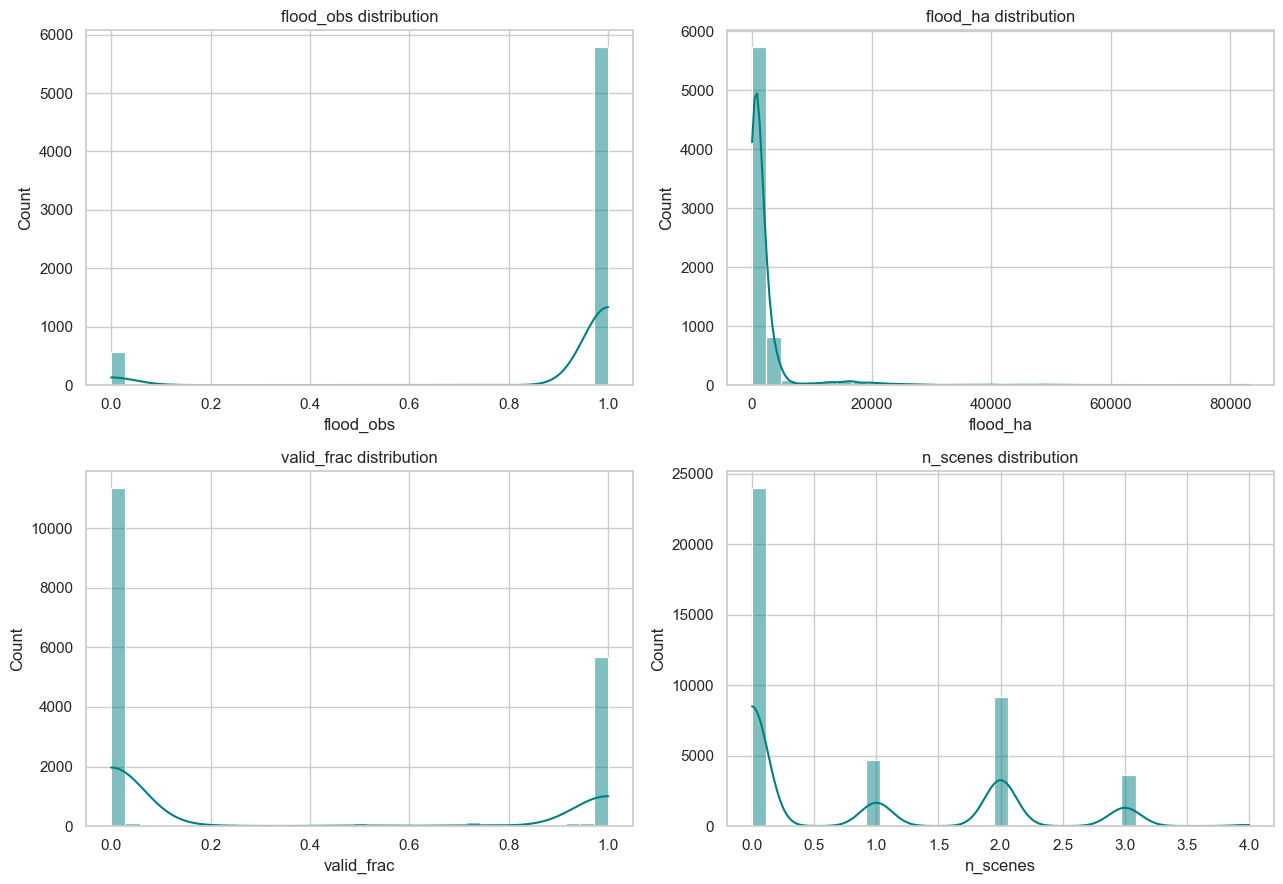


### rain_clean.csv
Shape: (41648, 21)
Date range: 2020-01-01 to 2025-12-31
Duplicate key rows: 0
Missing values by column:


,missing_rows
date,0
year,0
month,0
day,0
doy,0
unit_level,0
province,0
district,0
district_code,0
rain_chirps_mm,0


,count,mean,std,min,25%,50%,75%,max
rain_chirps_mm,41648.0,7.529,12.972,0.0,0.000,1.936,10.301,213.458
rain_imerg_mm,41648.0,6.955,13.401,0.0,0.111,1.821,8.072,242.502
rain_minutes,41648.0,250.716,297.120,0.0,14.516,140.769,385.177,1440.000
rain_hours,41648.0,4.179,4.952,0.0,0.242,2.346,6.420,24.000
rain_max_mmh,41648.0,2.382,3.179,0.0,0.137,1.303,3.437,39.324
rain_3d,41648.0,22.589,30.647,0.0,1.424,13.642,31.457,464.425
rain_7d,41648.0,52.658,57.652,0.0,12.716,39.590,71.731,646.122
rain_14d,41648.0,105.116,96.346,0.0,38.764,85.372,140.431,888.721
rain_30d,41648.0,224.787,177.241,0.0,98.140,192.829,296.733,1132.003
rain_up_mm,41648.0,7.258,11.057,0.0,0.248,3.270,10.011,162.911


,date,year,month,day,doy,unit_level,province,district,district_code,rain_chirps_mm,...,rain_minutes,rain_hours,rain_max_mmh,rain_3d,rain_7d,rain_14d,rain_30d,rain_up_mm,rain_up_3d,rain_up_7d
0,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Bang Khan,26738,0.0,...,0.000000,0.00000,0.000000,0.0,0.0,0.0,41.092725,0.0,0.000000,0.000000
1,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Cha-uat,26739,0.0,...,0.000000,0.00000,0.000000,0.0,0.0,0.0,62.813984,0.0,1.112329,1.270381
2,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Chawang,26740,0.0,...,3.666575,0.06111,0.160107,0.0,0.0,0.0,48.461352,0.0,1.277393,1.458899


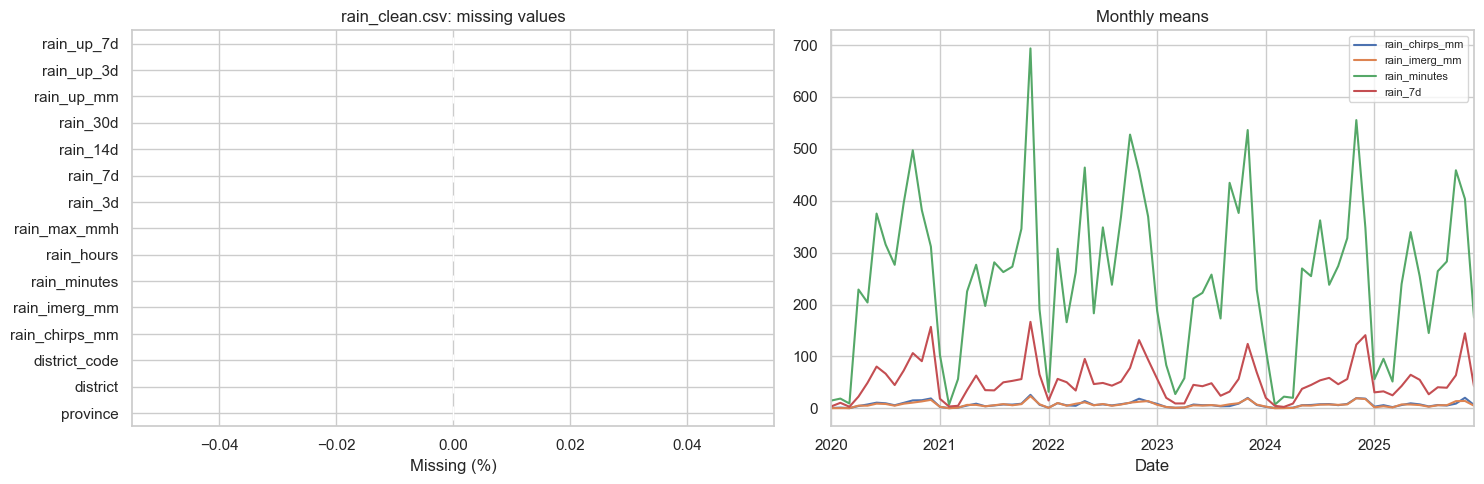

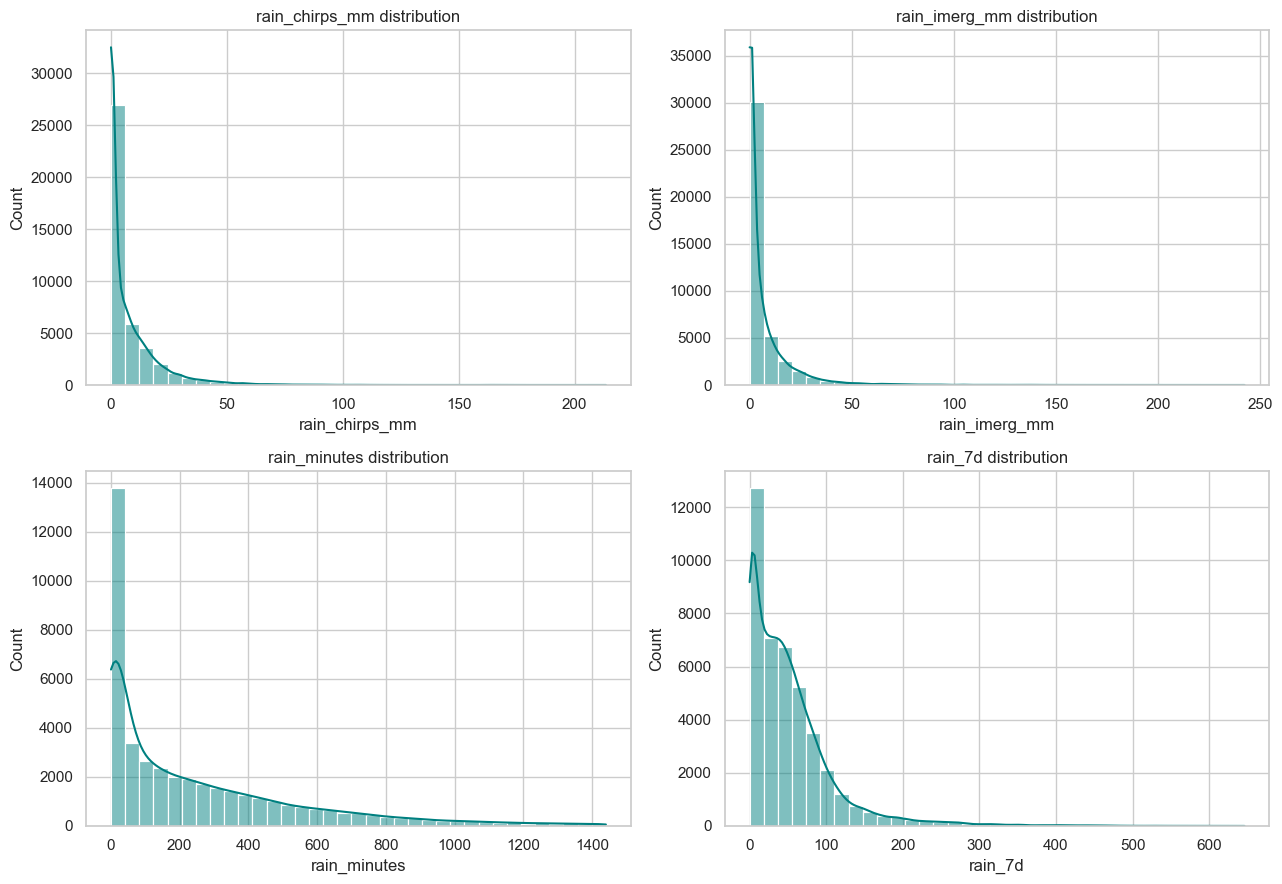


### static_terrain_soil_clean.csv
Shape: (19, 26)
Duplicate key rows: 0
Missing values by column:


,missing_rows
river_max_cms,1
unit_level,0
district,0
district_code,0
area_km2,0
lat,0
lon,0
elevation_m,0
slope_deg,0
province,0


,count,mean,std,min,25%,50%,75%,max
area_km2,19.0,1042.208,2162.928,1.708,383.477,559.091,749.525,9902.017
lat,19.0,8.430,0.388,7.957,8.142,8.374,8.569,9.331
lon,19.0,99.804,0.237,99.375,99.628,99.791,99.955,100.246
elevation_m,19.0,127.615,123.652,4.376,20.581,95.382,174.484,392.811
slope_deg,19.0,6.748,4.238,1.181,3.343,6.002,9.166,14.472
tpi_2km_m,19.0,0.755,2.705,-4.555,-0.122,0.116,1.042,9.563
bowl_frac,19.0,0.167,0.086,0.000,0.121,0.177,0.231,0.330
hand_m,19.0,35.663,32.772,0.676,5.967,25.076,53.194,97.069
frac_hand_lt5,19.0,0.551,0.271,0.178,0.363,0.441,0.783,0.991
frac_hand_lt10,19.0,0.657,0.232,0.243,0.510,0.633,0.866,1.000


,unit_level,province,district,district_code,area_km2,lat,lon,elevation_m,slope_deg,tpi_2km_m,...,sand_pct,lc_tree,lc_crop,impervious_built_frac,lc_water,lc_wetland,lc_mangrove,river_km_per_km2,river_max_cms,river_max_cms_missing
0,amphoe,นครศรีธรรมราช,Bang Khan,26738,472.431869,8.006266,99.489173,95.382076,6.002214,-0.275796,...,50.403300,0.934469,0.010361,0.004723,0.000418,0.000000,0.0,0.345977,46.043,0
1,amphoe,นครศรีธรรมราช,Cha-uat,26739,782.117424,7.956940,99.986625,24.432782,2.599895,-0.518158,...,45.660017,0.813197,0.027253,0.006604,0.007410,0.022857,0.0,0.430348,30.417,0
2,amphoe,นครศรีธรรมราช,Chawang,26740,874.657452,8.436024,99.526562,177.339235,8.895853,0.208115,...,49.282396,0.942864,0.003983,0.008794,0.005915,0.000090,0.0,0.376954,62.032,0


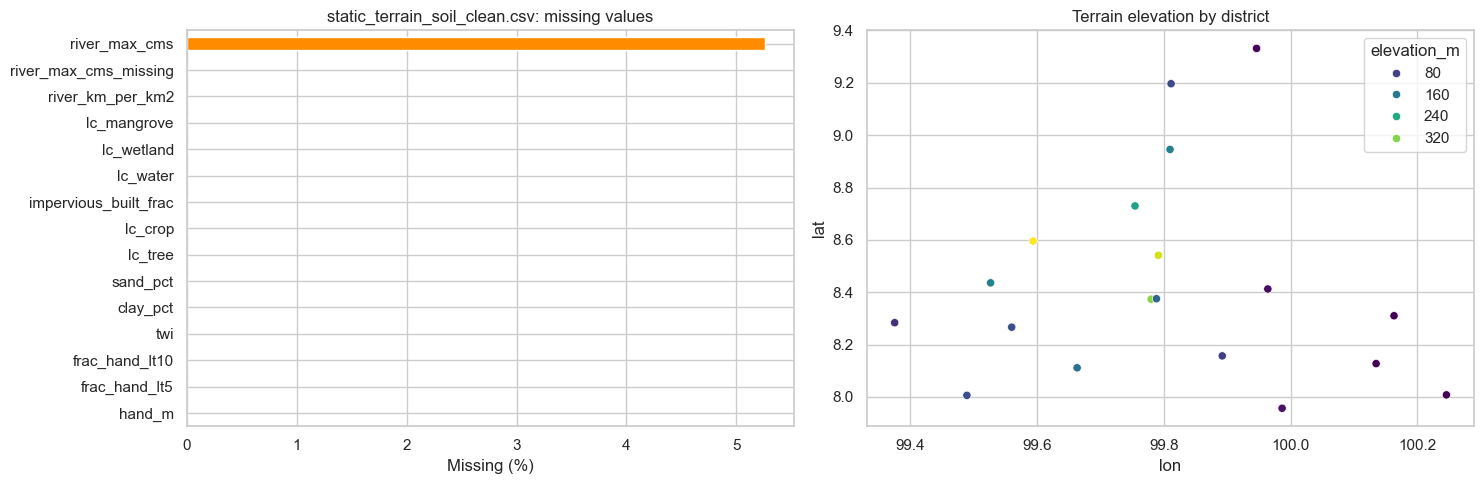

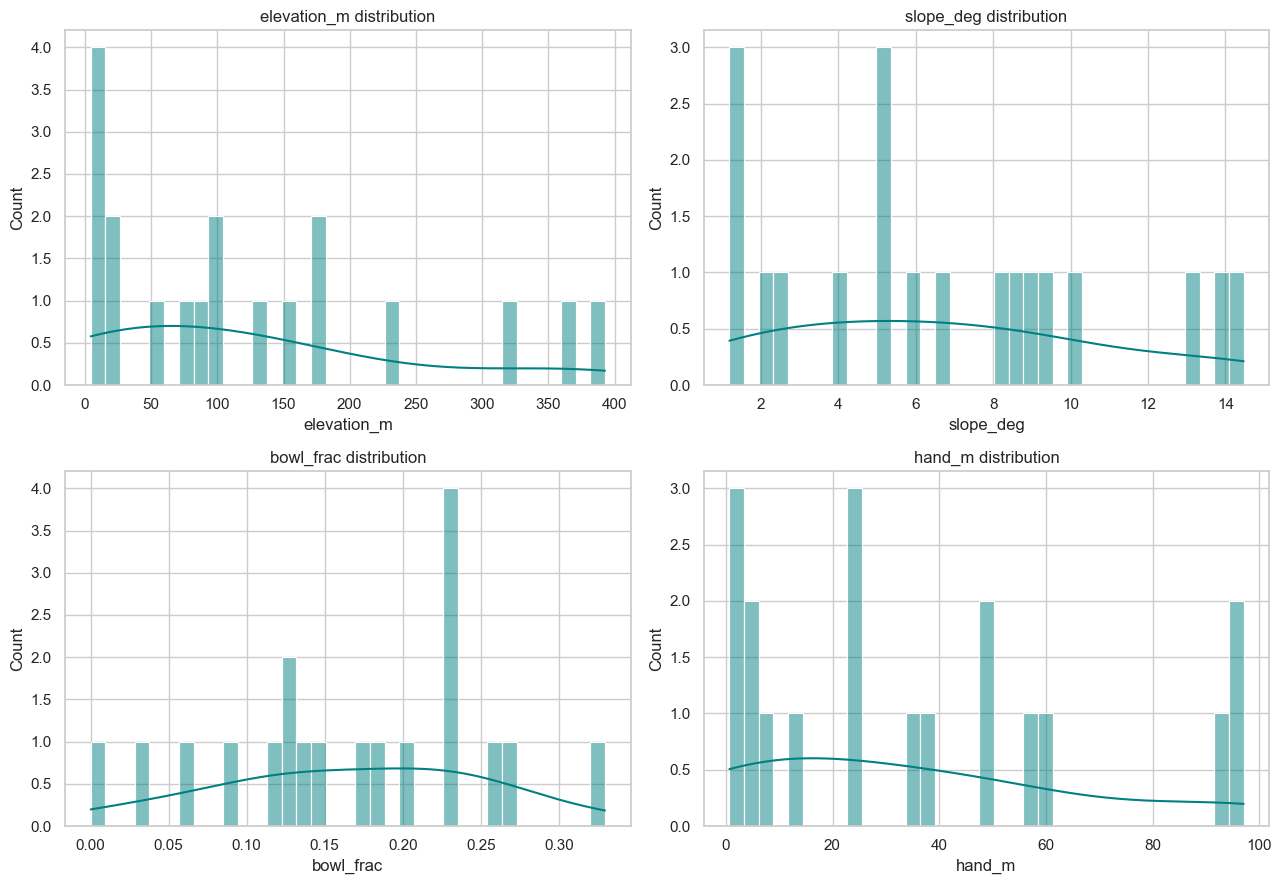


### 4_flood_recurrence.csv
Shape: (133, 11)
Rows per recurrence period:


,rows
period,
2020,19
2021,19
2022,19
2023,19
2024,19
2025,19
all,19


Duplicate key rows: 0
Missing values by column:


,missing_rows
period,0
unit_level,0
district,0
district_code,0
area_ha,0
flood_freq_mean,0
flood_count_mean,0
valid_scene_count_mean,0
flood_ever_ha,0
recurrent_ge2_ha,0


,count,mean,std,min,25%,50%,75%,max
area_ha,133.0,104220.818,211319.861,170.811,35481.553,55909.103,78211.742,990201.651
flood_freq_mean,133.0,0.023,0.010,0.003,0.017,0.022,0.027,0.057
flood_count_mean,133.0,2.046,2.316,0.152,0.937,1.211,1.785,10.762
valid_scene_count_mean,133.0,91.055,94.312,40.000,51.000,57.000,60.096,396.438
flood_ever_ha,133.0,967.642,2149.715,1.542,54.081,109.601,687.403,14427.473
recurrent_ge2_ha,133.0,709.033,1621.796,0.661,40.310,85.120,555.127,12140.850
recurrent_ge3_ha,133.0,562.019,1328.600,0.019,32.421,72.207,468.578,10733.978


,period,unit_level,district,district_code,area_ha,flood_freq_mean,flood_count_mean,valid_scene_count_mean,flood_ever_ha,recurrent_ge2_ha,recurrent_ge3_ha
0,all,amphoe,Bang Khan,26738,47243.186860,0.019870,5.980769,301.000000,16.725913,15.742032,12.790213
1,all,amphoe,Cha-uat,26739,78211.742418,0.021752,7.696947,355.303473,1171.077846,1007.114067,904.597480
2,all,amphoe,Chawang,26740,87465.745181,0.017052,5.115717,300.000000,204.897420,172.481883,154.423223


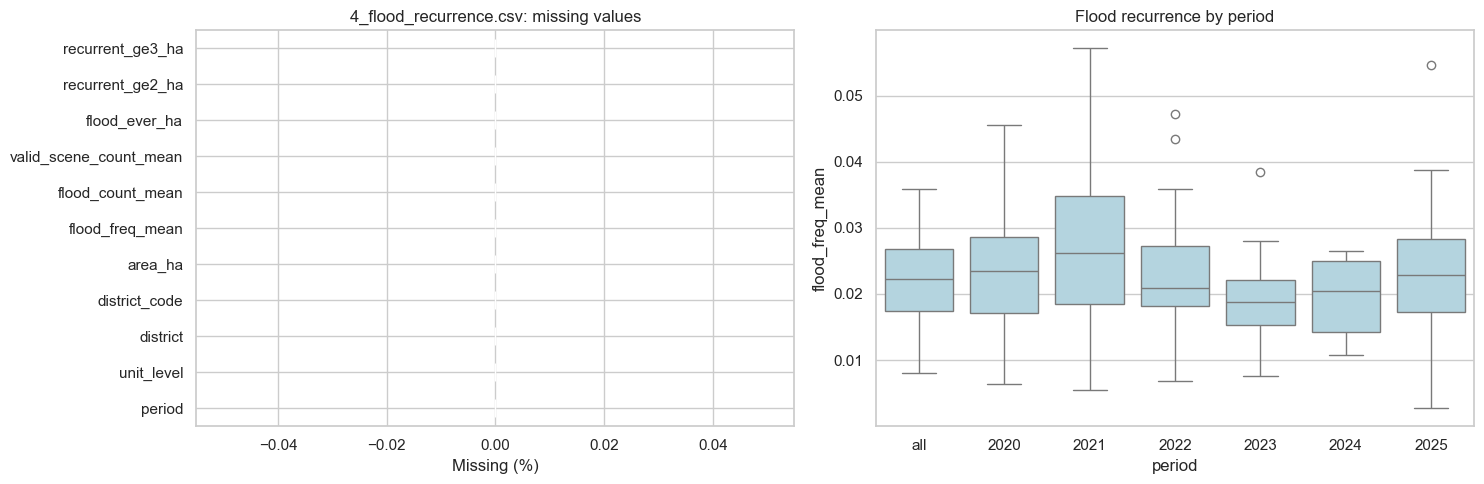

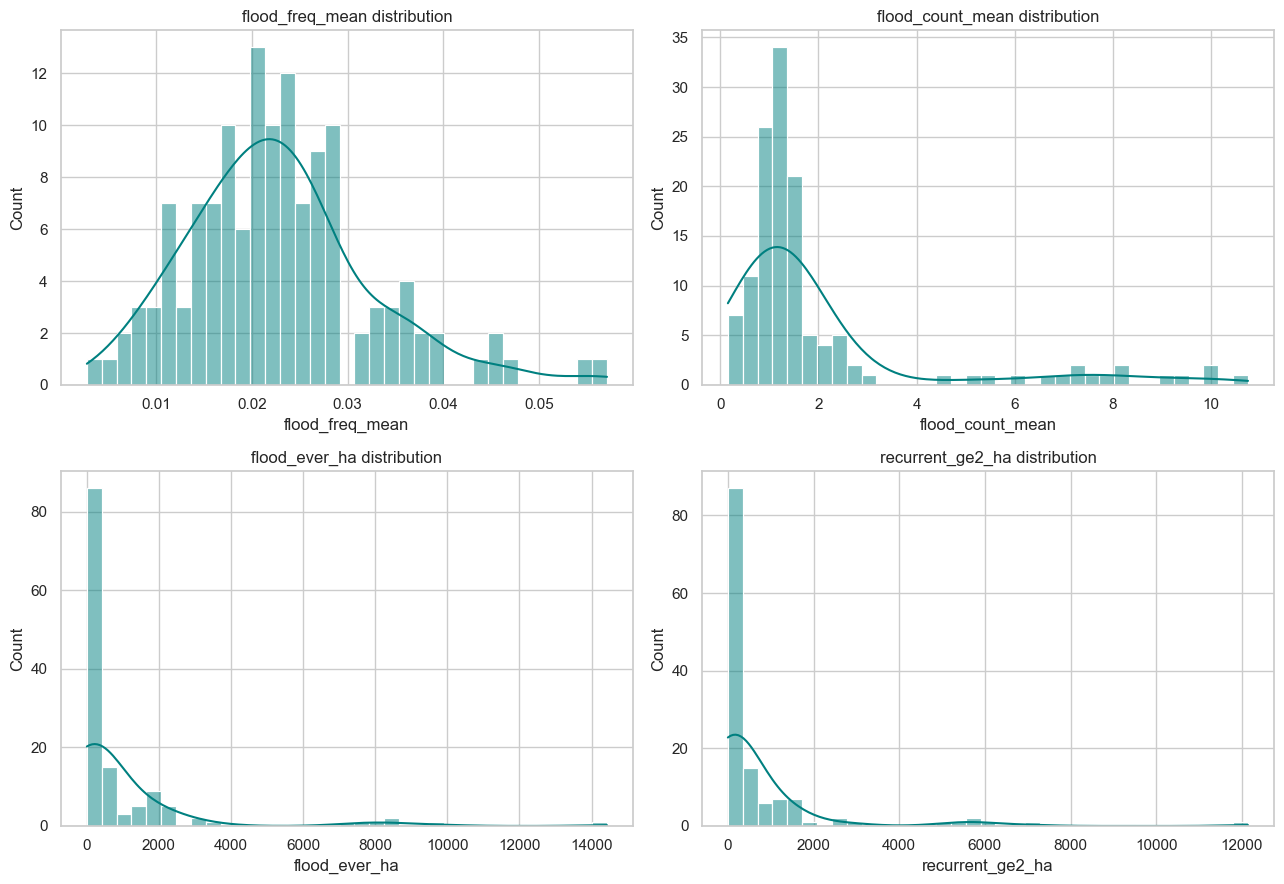


### nst_label_gfs_2020-01-01_to_2026-11-22.csv
Shape: (45324, 31)
Date range: 2020-01-01 to 2026-11-22
Duplicate key rows: 0
Missing values by column:


,missing_rows
flood_obs,38851
vv_db,38304
vh_db,38304
scene_time_utc,38303
orbit_pass,38303
relative_orbit,38303
platform,38303
angle_deg,37912
flood_area_ha,26064
wind_u_10m,2603


,count,mean,std,min,25%,50%,75%,max
flood_obs,6473.0,0.897,0.304,0.000,1.000,1.000,1.000,1.000
label_available,45324.0,0.143,0.350,0.000,0.000,0.000,0.000,1.000
flood_area_ha,19260.0,424.865,936.345,0.000,0.000,0.000,503.952,20732.193
valid_frac,45324.0,0.146,0.351,0.000,0.000,0.000,0.000,1.000
scene_count,45324.0,0.167,0.406,0.000,0.000,0.000,0.000,4.000
observed_area_ha,45324.0,8027.409,21792.956,0.000,0.000,0.000,0.000,116144.289
vv_db,7020.0,-7.961,0.995,-12.784,-8.388,-7.807,-7.340,-5.509
vh_db,7020.0,-14.555,1.018,-19.383,-14.949,-14.333,-13.914,-12.086
angle_deg,7412.0,38.640,4.029,30.825,35.553,38.460,41.447,46.194
forecast_hours,45252.0,72.000,0.000,72.000,72.000,72.000,72.000,72.000


,date,district_code,district,flood_obs,label_available,flood_area_ha,valid_frac,scene_count,observed_area_ha,vv_db,...,rain_next_48h_mm,rain_next_72h_mm,temperature_2m,relative_humidity_2m,wind_u_10m,wind_v_10m,up_rain_next_24h_mm,up_rain_next_48h_mm,up_rain_next_72h_mm,unit_level
0,2020-01-01,26738,Bang Khan,NaN,0,NaN,0.0,0,0.0,NaN,...,1.787343,1.886792,25.523061,78.927281,-4.234631,-0.678531,1.020627,2.325048,2.714212,amphoe
1,2020-01-01,26739,Cha-uat,NaN,0,NaN,0.0,0,0.0,NaN,...,2.620945,3.277433,26.737956,76.479311,-6.044054,-0.140493,1.246566,3.639217,4.918986,amphoe
2,2020-01-01,26740,Chawang,NaN,0,NaN,0.0,0,0.0,NaN,...,2.854596,3.765249,24.788737,81.213346,-2.801197,-0.554372,1.255247,2.904883,4.147986,amphoe


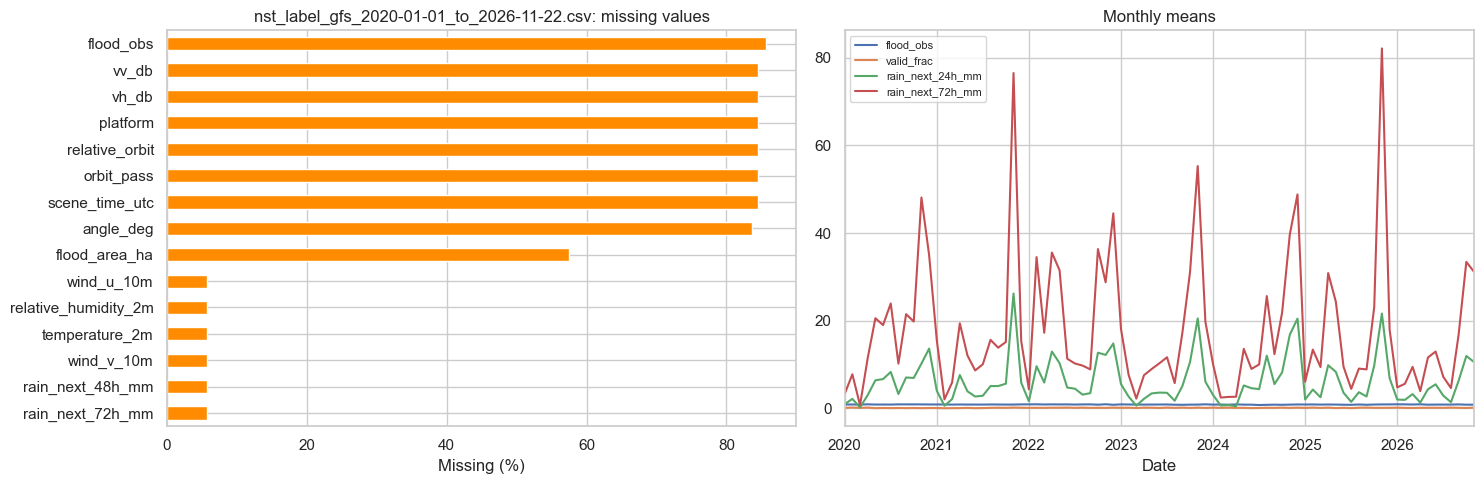

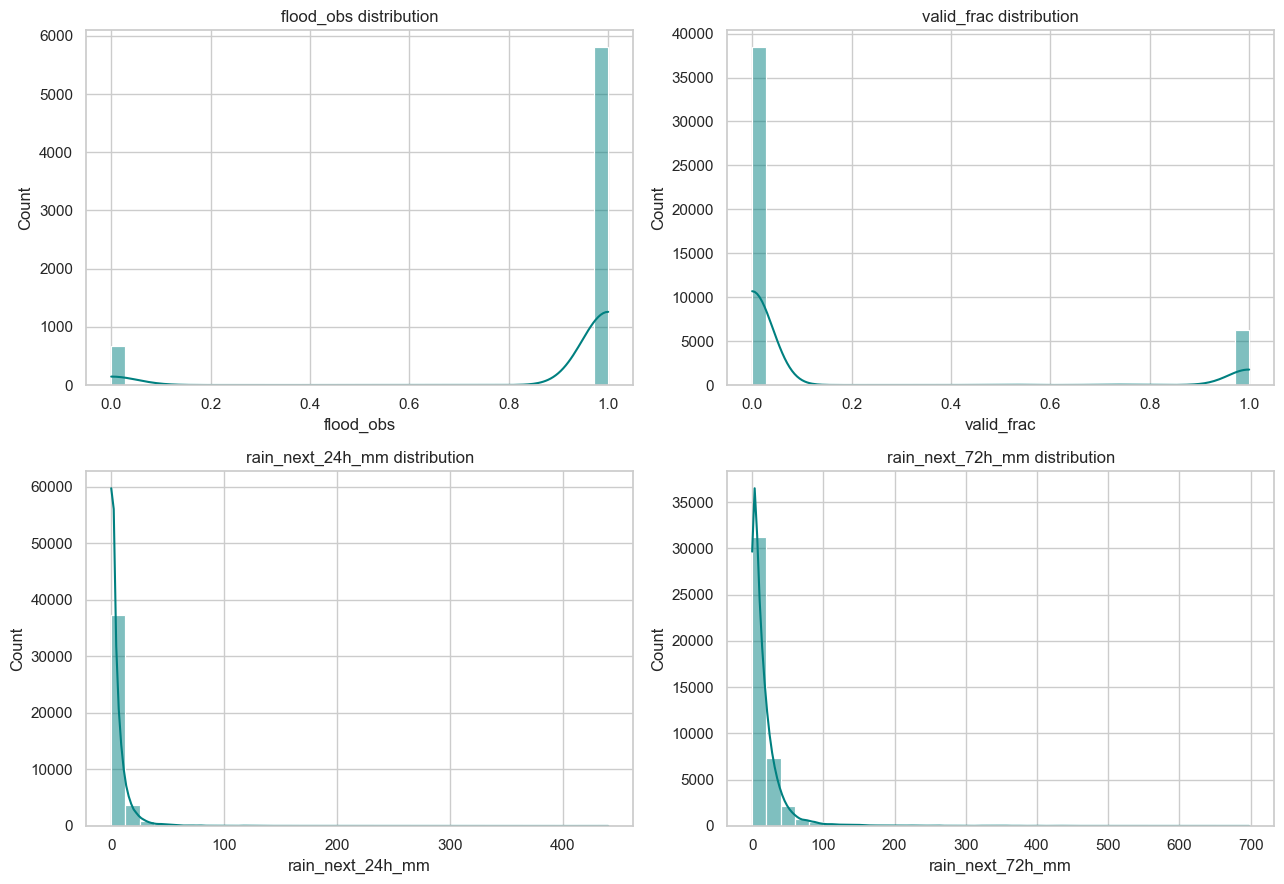

In [3]:
for filename, frame in source_frames.items():
    print(f"\n### {filename}")
    print(f"Shape: {frame.shape}")
    if "date" in frame.columns:
        print(f"Date range: {frame['date'].min().date()} to {frame['date'].max().date()}")
    if "period" in frame.columns:
        print("Rows per recurrence period:")
        display(frame["period"].value_counts().sort_index().rename("rows").to_frame())
    key_columns = DAILY_KEYS if "date" in frame.columns else (
        ["period", "unit_level", "district_code"] if "period" in frame.columns else DISTRICT_KEYS
    )
    print("Duplicate key rows:", int(frame.duplicated(key_columns).sum()))
    print("Missing values by column:")
    display(frame.isna().sum().sort_values(ascending=False).head(12).rename("missing_rows").to_frame())
    numeric = frame.select_dtypes(include="number")
    excluded = {"year", "month", "day", "doy", "district_code"}
    numeric = numeric[[column for column in numeric.columns if column not in excluded]]
    if not numeric.empty:
        display(numeric.describe().T.round(3).head(15))
    display(frame.head(3))

    plot_columns = [column for column in SOURCE_PLOT_COLUMNS[filename] if column in frame.columns]
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    missing_pct = frame.isna().mean().mul(100).sort_values().tail(15)
    missing_pct.plot(kind="barh", ax=axes[0], color="darkorange")
    axes[0].set(title=f"{filename}: missing values", xlabel="Missing (%)")
    if "date" in frame.columns and plot_columns:
        monthly = frame.set_index("date")[plot_columns].resample("MS").mean()
        monthly.plot(ax=axes[1])
        axes[1].set(title="Monthly means", xlabel="Date")
        axes[1].legend(fontsize=8)
    elif "period" in frame.columns and "flood_freq_mean" in frame.columns:
        sns.boxplot(data=frame, x="period", y="flood_freq_mean", ax=axes[1], color="lightblue")
        axes[1].set_title("Flood recurrence by period")
    elif {"lon", "lat", "elevation_m"}.issubset(frame.columns):
        sns.scatterplot(data=frame, x="lon", y="lat", hue="elevation_m", palette="viridis", ax=axes[1])
        axes[1].set_title("Terrain elevation by district")
    else:
        axes[1].axis("off")
    plt.tight_layout()
    plt.show()

    if plot_columns:
        fig, axes = plt.subplots(2, 2, figsize=(13, 9))
        for column, ax in zip(plot_columns, axes.flat):
            sns.histplot(data=frame, x=column, bins=35, kde=True, ax=ax, color="teal")
            ax.set_title(f"{column} distribution")
        for ax in axes.flat[len(plot_columns):]:
            ax.axis("off")
        plt.tight_layout()
        plt.show()


## 2. Data clean

Parse dates, normalize text, coerce numeric fields, and remove invalid or duplicate keys. Missing measurement values are preserved because they can indicate that no observation was available.

In [4]:
clean_frames = {}
key_map = {}
for filename, source in source_frames.items():
    frame = source.copy()
    if "date" in frame.columns:
        frame["date"] = pd.to_datetime(frame["date"], errors="coerce")
        keys = DAILY_KEYS
    elif "period" in frame.columns:
        frame["period"] = frame["period"].astype("string").str.strip()
        keys = ["period", "unit_level", "district_code"]
    else:
        keys = DISTRICT_KEYS

    text_columns = frame.select_dtypes(include=["object", "string"]).columns
    for column in text_columns:
        frame[column] = (frame[column].astype("string").str.strip()
                         .str.replace(r"\s+", " ", regex=True))
    for column in ["scene_time_utc", "gfs_issue_time", "gfs_valid_time"]:
        if column in frame.columns:
            frame[column] = pd.to_datetime(frame[column], errors="coerce", utc=True)
    frame["district_code"] = pd.to_numeric(frame["district_code"], errors="coerce")
    categorical_columns = {"unit_level", "province", "district", "period", "orbit_pass", "relative_orbit", "platform"}
    datetime_columns = {"date", "scene_time_utc", "gfs_issue_time", "gfs_valid_time"}
    for column in frame.columns:
        if column not in categorical_columns and column not in datetime_columns:
            frame[column] = pd.to_numeric(frame[column], errors="coerce")

    rows_before = len(frame)
    frame = frame.dropna(subset=keys).copy()
    frame["district_code"] = frame["district_code"].astype("int64")
    frame = frame.drop_duplicates()
    frame = frame.drop_duplicates(subset=keys, keep="first")
    if frame.duplicated(keys).any():
        raise ValueError(f"Duplicate keys remain in {filename}")
    clean_frames[filename] = frame
    key_map[filename] = keys
    print(f"{filename}: {rows_before:,} rows -> {len(frame):,} rows; removed {rows_before - len(frame):,}")

flood_labels = clean_frames["flood_history_clean.csv"]["flood_obs"].dropna()
if not flood_labels.isin([0, 1]).all():
    raise ValueError("flood_obs contains values other than 0, 1, or missing")


sea_level_clean.csv: 41,648 rows -> 41,648 rows; removed 0
humidity_pressure_soil_clean.csv: 41,648 rows -> 41,648 rows; removed 0
river_level_clean.csv: 41,648 rows -> 41,648 rows; removed 0
flood_history_clean.csv: 41,648 rows -> 41,648 rows; removed 0
rain_clean.csv: 41,648 rows -> 41,648 rows; removed 0
static_terrain_soil_clean.csv: 19 rows -> 19 rows; removed 0
4_flood_recurrence.csv: 133 rows -> 133 rows; removed 0
nst_label_gfs_2020-01-01_to_2026-11-22.csv: 45,324 rows -> 45,324 rows; removed 0


## 3. Data prep: merge daily, static, and recurrence data

Daily files are joined one-to-one on `date + unit_level + district_code`. Static district attributes are added many-to-one. The seven recurrence periods (`all`, 2020?2025) are pivoted into separate columns before joining, so the final table stays at daily district granularity.

In [5]:
def values_match(left, right):
    if pd.api.types.is_numeric_dtype(left) and pd.api.types.is_numeric_dtype(right):
        return np.isclose(
            left.to_numpy(dtype="float64"),
            right.to_numpy(dtype="float64"),
            rtol=1e-10,
            atol=1e-12,
            equal_nan=True,
        ).all()
    left_values = left.astype("string").fillna("<NA>").to_numpy()
    right_values = right.astype("string").fillna("<NA>").to_numpy()
    return np.array_equal(left_values, right_values)


def assert_matching_metadata(left, right, keys, filename):
    left_index = pd.MultiIndex.from_frame(left[keys])
    right_index = pd.MultiIndex.from_frame(right[keys])
    if not right_index.is_unique:
        raise ValueError(f"Right-side merge keys are not unique in {filename}")
    left_unique = left_index.unique()
    if len(left_unique) != len(right_index) or not left_unique.isin(right_index).all() or not right_index.isin(left_unique).all():
        raise ValueError(f"Key set mismatch in {filename}")
    aligned = right.set_index(keys).reindex(left_index)
    shared = [column for column in left.columns if column in right.columns and column not in keys]
    conflicts = [column for column in shared
                 if not values_match(left[column].reset_index(drop=True), aligned[column].reset_index(drop=True))]
    if conflicts:
        raise ValueError(f"Conflicting shared metadata in {filename}: {conflicts}")
    return shared


# Give the two unrelated source counts distinct names before combining.
clean_frames["river_level_clean.csv"] = clean_frames["river_level_clean.csv"].rename(
    columns={"n_scenes": "river_n_scenes"}
)
clean_frames["flood_history_clean.csv"] = clean_frames["flood_history_clean.csv"].rename(
    columns={"n_scenes": "flood_n_scenes"}
)

merged_df = clean_frames["sea_level_clean.csv"].copy()
for filename in [
    "humidity_pressure_soil_clean.csv",
    "river_level_clean.csv",
    "flood_history_clean.csv",
    "rain_clean.csv",
]:
    frame = clean_frames[filename]
    shared = assert_matching_metadata(merged_df, frame, DAILY_KEYS, filename)
    additions = frame.drop(columns=shared)
    merged_df = merged_df.merge(
        additions, on=DAILY_KEYS, how="left", validate="one_to_one", sort=False
    )
    print(f"Merged {filename}: {len(additions.columns) - len(DAILY_KEYS)} new columns")

static_df = clean_frames["static_terrain_soil_clean.csv"]
static_shared = assert_matching_metadata(merged_df, static_df, DISTRICT_KEYS, "static_terrain_soil_clean.csv")
static_additions = static_df.drop(columns=static_shared)
merged_df = merged_df.merge(
    static_additions, on=DISTRICT_KEYS, how="left", validate="many_to_one", sort=False
)
if merged_df[static_additions.columns.difference(DISTRICT_KEYS)].isna().all(axis=1).any():
    raise ValueError("Some daily rows did not match static district attributes")

recurrence_df = clean_frames["4_flood_recurrence.csv"]
recurrence_metrics = [column for column in recurrence_df.columns
                      if column not in {"period", "unit_level", "district", "district_code"}]
recurrence_wide = recurrence_df.pivot(
    index=DISTRICT_KEYS, columns="period", values=recurrence_metrics
)
recurrence_wide.columns = [
    f"recurrence_{metric}_{period}" for metric, period in recurrence_wide.columns
]
recurrence_wide = recurrence_wide.reset_index()
if recurrence_wide.duplicated(DISTRICT_KEYS).any():
    raise ValueError("Recurrence data is not unique by district after pivot")
merged_df = merged_df.merge(
    recurrence_wide, on=DISTRICT_KEYS, how="left", validate="many_to_one", sort=False
)

if merged_df.columns.duplicated().any():
    duplicate_columns = merged_df.columns[merged_df.columns.duplicated()].tolist()
    raise ValueError(f"Duplicate output columns: {duplicate_columns}")
if merged_df.duplicated(DAILY_KEYS).any():
    raise ValueError("Daily merge created duplicate date + district rows")
if merged_df.isna().all(axis=0).any():
    empty_columns = merged_df.columns[merged_df.isna().all(axis=0)].tolist()
    raise ValueError(f"All-empty columns after merge: {empty_columns}")
merged_df = merged_df.sort_values(DAILY_KEYS).reset_index(drop=True)
print(f"Merged table shape: {merged_df.shape}")
print(f"Recurrence periods included: {sorted(recurrence_df['period'].astype(str).unique())}")
display(merged_df.head())

gfs_filename = "nst_label_gfs_2020-01-01_to_2026-11-22.csv"
gfs_df = clean_frames[gfs_filename].copy()
if not gfs_df["flood_obs"].dropna().isin([0, 1]).all():
    raise ValueError("The GFS flood_obs column must contain only 0, 1, or missing values.")
if not gfs_df["label_available"].eq(gfs_df["flood_obs"].notna().astype("int8")).all():
    raise ValueError("label_available does not match the GFS flood_obs labels.")

legacy_label_map = {
    "flood_obs": "flood_obs_legacy",
    "valid_frac": "valid_frac_legacy",
    "flood_obs_available": "flood_obs_available_legacy",
    "flood_obs_missing": "flood_obs_missing_legacy",
    "valid_frac_missing": "valid_frac_missing_legacy",
}
legacy_flood = clean_frames["flood_history_clean.csv"].copy()
legacy_flood = legacy_flood.rename(columns={key: value for key, value in legacy_label_map.items() if key in legacy_flood})
label_overlap = legacy_flood[[*DAILY_KEYS, "flood_obs_legacy"]].merge(
    gfs_df[[*DAILY_KEYS, "flood_obs"]], on=DAILY_KEYS, how="inner", validate="one_to_one"
)
both_labels = label_overlap["flood_obs_legacy"].notna() & label_overlap["flood_obs"].notna()
label_disagreements = int(
    label_overlap.loc[both_labels, "flood_obs_legacy"].ne(label_overlap.loc[both_labels, "flood_obs"]).sum()
)
clean_frames["flood_history_clean.csv"] = legacy_flood
gfs_df["flood_obs_available"] = gfs_df["label_available"].astype("int8")
gfs_df["flood_obs_missing"] = (1 - gfs_df["flood_obs_available"]).astype("int8")
gfs_df["valid_frac_missing"] = gfs_df["valid_frac"].isna().astype("int8")

daily_source_order = [
    "sea_level_clean.csv",
    "humidity_pressure_soil_clean.csv",
    "river_level_clean.csv",
    "flood_history_clean.csv",
    "rain_clean.csv",
    gfs_filename,
]
daily_frames_for_merge = {}
for filename in daily_source_order:
    frame = gfs_df.copy() if filename == gfs_filename else clean_frames[filename].copy()
    frame = frame.drop(columns=[column for column in ["year", "month", "day", "doy", "district", "province"] if column in frame])
    daily_frames_for_merge[filename] = frame

merged_df = None
for filename, frame in daily_frames_for_merge.items():
    if merged_df is None:
        merged_df = frame.copy()
        continue
    shared_measurements = sorted((set(merged_df.columns) & set(frame.columns)) - set(DAILY_KEYS))
    if shared_measurements:
        raise ValueError(f"Unexpected shared measurements in {filename}: {shared_measurements}")
    previous_rows = len(merged_df)
    merged_df = merged_df.merge(frame, on=DAILY_KEYS, how="outer", validate="one_to_one", sort=False)
    print(f"Outer-merged {filename}: {previous_rows:,} -> {len(merged_df):,} daily keys")

merged_df["year"] = merged_df["date"].dt.year.astype("int16")
merged_df["month"] = merged_df["date"].dt.month.astype("int8")
merged_df["day"] = merged_df["date"].dt.day.astype("int8")
merged_df["doy"] = merged_df["date"].dt.dayofyear.astype("int16")
static_df = clean_frames["static_terrain_soil_clean.csv"]
merged_df = merged_df.merge(static_df, on=DISTRICT_KEYS, how="left", validate="many_to_one", sort=False)
if merged_df["district"].isna().any():
    raise ValueError("Some daily rows did not match static district attributes.")

recurrence_df = clean_frames["4_flood_recurrence.csv"]
recurrence_metrics = [column for column in recurrence_df if column not in {"period", "unit_level", "district", "district_code", "province"}]
recurrence_wide = recurrence_df.pivot(index=DISTRICT_KEYS, columns="period", values=recurrence_metrics)
recurrence_wide.columns = [f"recurrence_{metric}_{period}" for metric, period in recurrence_wide.columns]
recurrence_wide = recurrence_wide.reset_index()
merged_df = merged_df.merge(recurrence_wide, on=DISTRICT_KEYS, how="left", validate="many_to_one", sort=False)
merged_df = merged_df.sort_values(DAILY_KEYS).reset_index(drop=True)
if merged_df.duplicated(DAILY_KEYS).any() or merged_df.columns.duplicated().any():
    raise ValueError("The rebuilt merge contains duplicate keys or columns.")
print(f"Rebuilt from all clean_dataset daily sources: {merged_df.shape[0]:,} rows x {merged_df.shape[1]} columns")
print(f"Date range: {merged_df['date'].min().date()} to {merged_df['date'].max().date()}")
print(f"Canonical new labels: {int(merged_df['flood_obs'].eq(0).sum()):,} no-flood; {int(merged_df['flood_obs'].eq(1).sum()):,} flood; {int(merged_df['flood_obs'].isna().sum()):,} unlabeled")
print(f"Old/new label disagreements retained in flood_obs_legacy: {label_disagreements:,}")
display(merged_df.head())


Merged humidity_pressure_soil_clean.csv: 36 new columns
Merged river_level_clean.csv: 13 new columns
Merged flood_history_clean.csv: 12 new columns
Merged rain_clean.csv: 12 new columns
Merged table shape: (41648, 162)
Recurrence periods included: ['2020', '2021', '2022', '2023', '2024', '2025', 'all']


,date,year,month,day,doy,unit_level,province,district,district_code,sea_level_cmems_m,...,recurrence_recurrent_ge2_ha_2024,recurrence_recurrent_ge2_ha_2025,recurrence_recurrent_ge2_ha_all,recurrence_recurrent_ge3_ha_2020,recurrence_recurrent_ge3_ha_2021,recurrence_recurrent_ge3_ha_2022,recurrence_recurrent_ge3_ha_2023,recurrence_recurrent_ge3_ha_2024,recurrence_recurrent_ge3_ha_2025,recurrence_recurrent_ge3_ha_all
0,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Bang Khan,26738,NaN,...,5.903075,5.903309,15.742032,5.903425,4.919770,7.871279,7.870654,3.935735,5.903309,12.790213
1,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Cha-uat,26739,NaN,...,400.464029,663.987049,1007.114067,271.501003,330.008999,391.865744,418.285311,318.338090,554.208657,904.597480
2,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Chawang,26740,NaN,...,101.197695,116.469278,172.481883,47.204050,75.445489,94.115770,77.072230,77.654133,94.089609,154.423223
3,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Chian Yai,26741,NaN,...,349.554432,387.170805,1102.774621,468.578176,569.328266,380.086680,316.590926,256.592580,311.528059,935.823241
4,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Hua Sai,26742,NaN,...,1231.365073,1435.450894,2879.708218,1027.773585,1426.388235,1002.799277,680.145255,929.318995,1180.649619,2584.612570


Outer-merged humidity_pressure_soil_clean.csv: 41,648 -> 41,648 daily keys
Outer-merged river_level_clean.csv: 41,648 -> 41,648 daily keys
Outer-merged flood_history_clean.csv: 41,648 -> 41,648 daily keys
Outer-merged rain_clean.csv: 41,648 -> 41,648 daily keys
Outer-merged nst_label_gfs_2020-01-01_to_2026-11-22.csv: 41,648 -> 47,516 daily keys
Rebuilt from all clean_dataset daily sources: 47,516 rows x 192 columns
Date range: 2020-01-01 to 2026-11-22
Canonical new labels: 668 no-flood; 5,805 flood; 41,043 unlabeled
Old/new label disagreements retained in flood_obs_legacy: 569


,date,unit_level,district_code,sea_level_cmems_m,sea_level_hycom_mean_m,sea_level_hycom_max_m,sea_level_hycom_min_m,sea_level_cmems_m_missing,sea_level_hycom_mean_m_missing,sea_level_hycom_max_m_missing,...,recurrence_recurrent_ge2_ha_2024,recurrence_recurrent_ge2_ha_2025,recurrence_recurrent_ge2_ha_all,recurrence_recurrent_ge3_ha_2020,recurrence_recurrent_ge3_ha_2021,recurrence_recurrent_ge3_ha_2022,recurrence_recurrent_ge3_ha_2023,recurrence_recurrent_ge3_ha_2024,recurrence_recurrent_ge3_ha_2025,recurrence_recurrent_ge3_ha_all
0,2020-01-01,amphoe,26738,NaN,0.729109,0.771184,0.679884,1.0,0.0,0.0,...,5.903075,5.903309,15.742032,5.903425,4.919770,7.871279,7.870654,3.935735,5.903309,12.790213
1,2020-01-01,amphoe,26739,NaN,0.729109,0.771184,0.679884,1.0,0.0,0.0,...,400.464029,663.987049,1007.114067,271.501003,330.008999,391.865744,418.285311,318.338090,554.208657,904.597480
2,2020-01-01,amphoe,26740,NaN,0.729109,0.771184,0.679884,1.0,0.0,0.0,...,101.197695,116.469278,172.481883,47.204050,75.445489,94.115770,77.072230,77.654133,94.089609,154.423223
3,2020-01-01,amphoe,26741,NaN,0.729109,0.771184,0.679884,1.0,0.0,0.0,...,349.554432,387.170805,1102.774621,468.578176,569.328266,380.086680,316.590926,256.592580,311.528059,935.823241
4,2020-01-01,amphoe,26742,NaN,0.729109,0.771184,0.679884,1.0,0.0,0.0,...,1231.365073,1435.450894,2879.708218,1027.773585,1426.388235,1002.799277,680.145255,929.318995,1180.649619,2584.612570


## 4. EDA on the combined data

Combined shape: 47,516 rows x 192 columns
Date range: 2020-01-01 to 2026-11-22
Rows by unit level:


,rows
unit_level,
amphoe,45324
province,2192


Prepared data types:


,dtype
date,datetime64[ns]
unit_level,string
district_code,int64
sea_level_cmems_m,float64
sea_level_hycom_mean_m,float64
...,...
recurrence_recurrent_ge3_ha_2022,float64
recurrence_recurrent_ge3_ha_2023,float64
recurrence_recurrent_ge3_ha_2024,float64
recurrence_recurrent_ge3_ha_2025,float64


Missing values by column (top 25):


,missing_rows
river_water_excess,41386
river_water_frac,41386
river_water_ha,41386
flood_obs_legacy,41167
flood_obs,41043
flood_ha,40552
vv_db,40496
vh_db,40496
scene_time_utc,40495
platform,40495


Numeric summary:


,count,mean,std,min,25%,50%,75%,max
sea_level_cmems_m,24890.0,0.701,0.103,0.467,0.624,0.677,0.767,1.029
sea_level_hycom_mean_m,32490.0,0.646,0.069,0.434,0.596,0.639,0.692,0.875
sea_level_hycom_max_m,32490.0,0.678,0.072,0.464,0.624,0.671,0.724,0.923
sea_level_hycom_min_m,32490.0,0.614,0.068,0.404,0.566,0.608,0.659,0.825
sea_level_cmems_m_missing,41648.0,0.402,0.490,0.000,0.000,0.000,1.000,1.000
sea_level_hycom_mean_m_missing,41648.0,0.220,0.414,0.000,0.000,0.000,0.000,1.000
sea_level_hycom_max_m_missing,41648.0,0.220,0.414,0.000,0.000,0.000,0.000,1.000
sea_level_hycom_min_m_missing,41648.0,0.220,0.414,0.000,0.000,0.000,0.000,1.000
sea_level_available_count,41648.0,2.938,1.120,1.000,3.000,3.000,4.000,4.000
rh_pct,39456.0,82.771,7.543,48.766,78.629,83.547,88.060,99.354


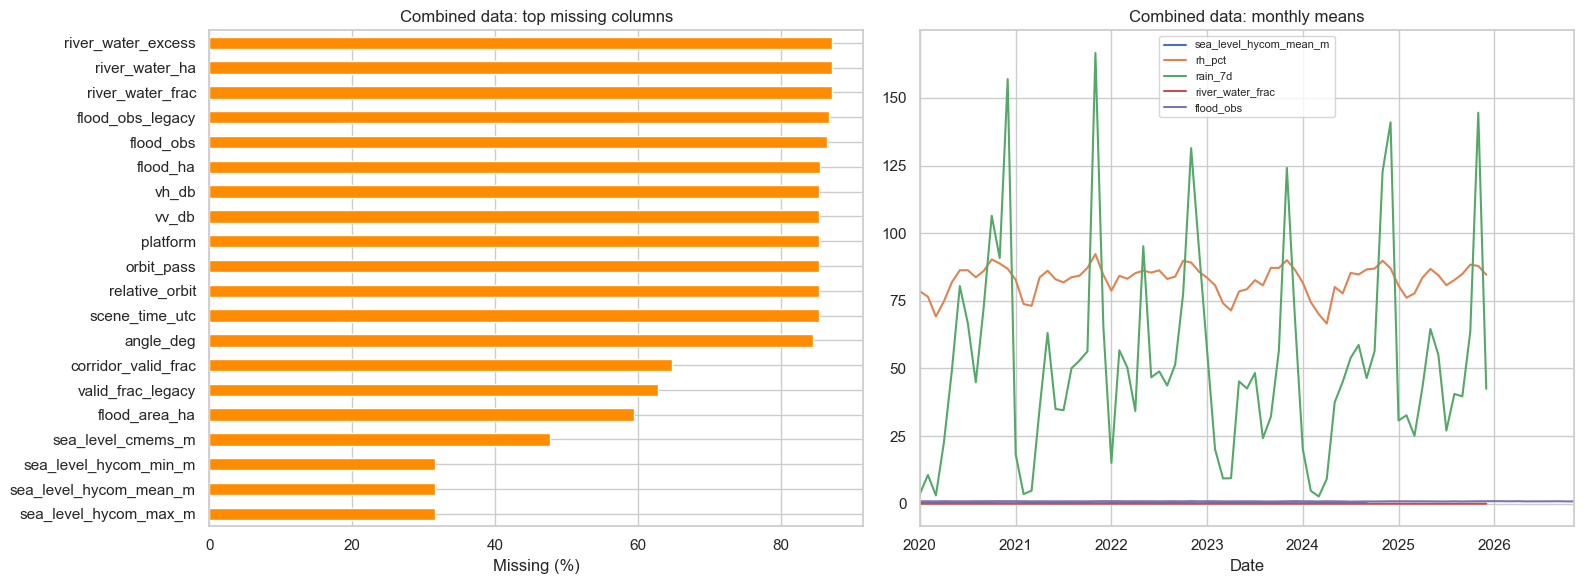

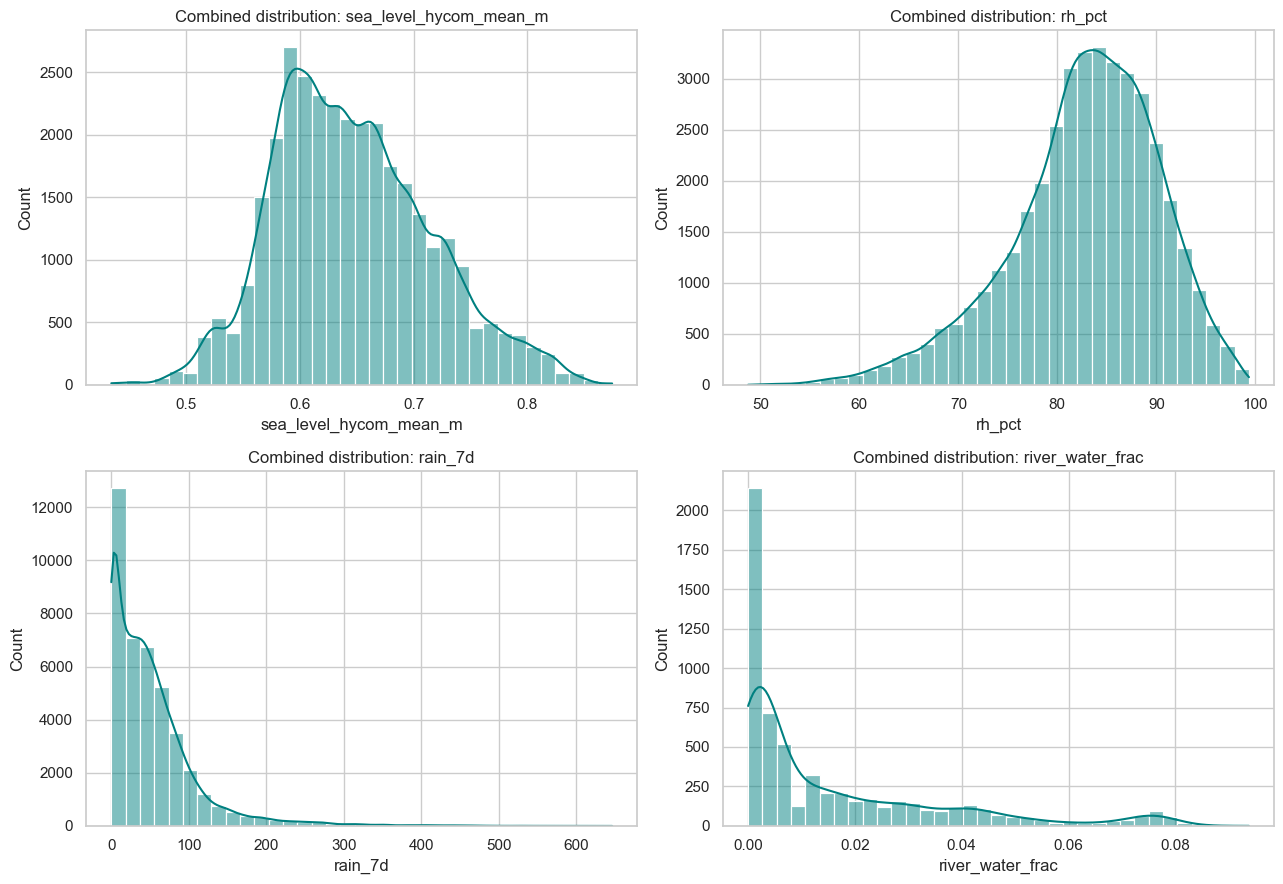

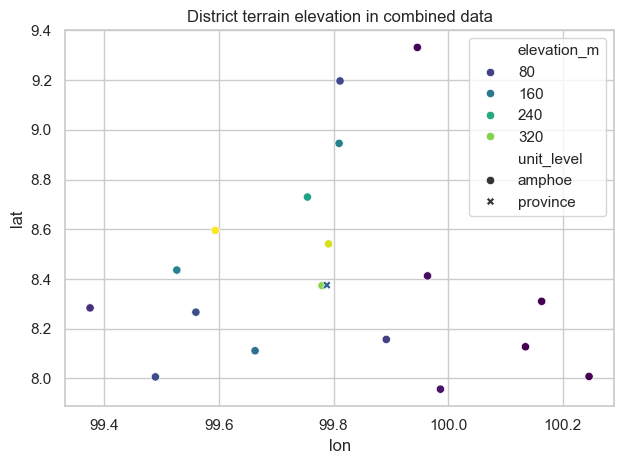

In [6]:
print(f"Combined shape: {merged_df.shape[0]:,} rows x {merged_df.shape[1]} columns")
print(f"Date range: {merged_df['date'].min().date()} to {merged_df['date'].max().date()}")
print("Rows by unit level:")
display(merged_df["unit_level"].value_counts().to_frame("rows"))
print("Prepared data types:")
display(merged_df.dtypes.astype(str).rename("dtype").to_frame())
print("Missing values by column (top 25):")
display(merged_df.isna().sum().sort_values(ascending=False).head(25).rename("missing_rows").to_frame())
print("Numeric summary:")
key_and_calendar = {"district_code", "year", "month", "day", "doy"}
numeric_columns = [column for column in merged_df.select_dtypes(include="number").columns
                   if column not in key_and_calendar]
display(merged_df[numeric_columns].describe().T.round(3).head(30))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
missing_pct = merged_df.isna().mean().mul(100).sort_values().tail(20)
missing_pct.plot(kind="barh", ax=axes[0], color="darkorange")
axes[0].set(title="Combined data: top missing columns", xlabel="Missing (%)")
monthly_columns = [column for column in [
    "sea_level_hycom_mean_m", "rh_pct", "rain_7d", "river_water_frac", "flood_obs"
] if column in merged_df.columns]
monthly = merged_df.set_index("date")[monthly_columns].resample("MS").mean()
monthly.plot(ax=axes[1])
axes[1].set(title="Combined data: monthly means", xlabel="Date")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for column, ax in zip(monthly_columns[:4], axes.flat):
    sns.histplot(data=merged_df, x=column, bins=35, kde=True, ax=ax, color="teal")
    ax.set_title(f"Combined distribution: {column}")
for ax in axes.flat[min(len(monthly_columns), 4):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

if {"lon", "lat", "elevation_m"}.issubset(merged_df.columns):
    district_points = merged_df[["unit_level", "district_code", "lon", "lat", "elevation_m"]].drop_duplicates("district_code")
    sns.scatterplot(data=district_points, x="lon", y="lat", hue="elevation_m", style="unit_level", palette="viridis")
    plt.title("District terrain elevation in combined data")
    plt.tight_layout()
    plt.show()


## 5. Save the merged CSV

In [7]:
output_dir = project_dir / "merge_dataset"
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / "all_clean_data_merged.csv"
saved_for_csv = merged_df.copy()
saved_for_csv["date"] = saved_for_csv["date"].dt.strftime("%Y-%m-%d")
saved_for_csv.to_csv(output_path, index=False, encoding="utf-8-sig")

saved_df = pd.read_csv(output_path, encoding="utf-8-sig", parse_dates=["date"], low_memory=False)
assert saved_df.shape == merged_df.shape
assert not saved_df.duplicated(DAILY_KEYS).any()
assert saved_df.columns.tolist() == merged_df.columns.tolist()
print(f"Saved: {output_path}")
print(f"File size: {output_path.stat().st_size:,} bytes")
print(f"CSV shape: {saved_df.shape}")


Saved: c:\Users\sitti\OneDrive\Desktop\Nahh ahhh v4\merge_dataset\all_clean_data_merged.csv
File size: 108,741,643 bytes
CSV shape: (47516, 192)
